In [1]:
# Imports
import pandas as pd
import seaborn as sns
import pickle 
import settings

from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score

climate_data = pd.read_csv(settings.TRAINING_DATA_PATH)


In [2]:
# Get idea about dataset
climate_data.shape


(1812, 11)

In [3]:
# Get idea about dataset
climate_data.describe()

,t_inside,h_inside,t_outside,h_outside,prev_t_inside,prev_h_inside,prev_t_outside,prev_h_outside,fanTargetSpeed
count,1812.000000,1812.000000,1812.000000,1812.000000,1812.000000,1812.000000,1812.000000,1812.000000,1812.000000
mean,21.581678,55.054967,21.820144,52.898731,21.580519,55.056181,21.819757,52.899338,62.954746
std,2.700413,4.650841,2.469909,6.001738,2.700218,4.650798,2.469397,6.003587,21.561750
min,17.100000,46.900002,18.500000,41.099998,17.100000,46.900002,18.500000,41.099998,0.000000
25%,19.299999,51.599998,19.600000,48.400002,19.299999,51.599998,19.600000,48.400002,45.000000
50%,20.400000,53.200001,21.100000,49.700001,20.400000,53.200001,21.100000,49.700001,63.000000
75%,24.025000,59.000000,23.900000,58.925001,24.025000,59.000000,23.900000,59.000000,82.000000
max,27.100000,68.599998,26.700001,68.099998,27.100000,68.599998,26.700001,68.099998,99.000000


In [4]:
# Prepare data (defining x and y)
climate_data['Heating'] = climate_data['Heating'].astype(bool)
inputSet = climate_data.drop(columns=['t_inside', 'h_inside', 'timestamp'])
outputSet = climate_data[['t_inside', 'h_inside']]

In [5]:
# Splitting Data into train- and testdata
input_train, input_test, output_train, output_test = train_test_split(inputSet, outputSet, test_size=0.2)
input_train.shape, output_train.shape, input_test.shape, output_test.shape

((1449, 8), (1449, 2), (363, 8), (363, 2))

In [6]:
# Create Model
model = linear_model.LinearRegression()
model.fit(input_train, output_train)

LinearRegression()

In [7]:
# Make Predictions
test_predictions = model.predict(input_test)

In [8]:
# Model Performance

model_mse = mean_squared_error(output_test, test_predictions)
model_r2_score = r2_score(output_test, test_predictions)
score = model.score(input_test, output_test)

print("Score: ", score)
print("Coefficients: ", model.coef_)
print("Intercept: ", model.intercept_)
print("Mean squared error (MSE): ", model_mse)
print("Coefficient of determination (R^2): ", model_r2_score)
#print("Mean absolute error (MEA): ", model.mea)

Score:  0.9977376641423265
Coefficients:  [[ 5.96006345e-01 -3.61928689e-02  7.54045922e-01 -3.89568423e-02
  -3.55131555e-01  7.85835164e-02 -1.28765998e-04 -8.14784145e-03]
 [-6.66595202e-01  4.60250041e-01 -8.78945614e-01  7.59728007e-01
   1.52215960e+00 -2.29391015e-01  1.59813358e-04 -3.60866488e-03]]
Intercept:  [-0.03336919  1.3072314 ]
Mean squared error (MSE):  0.0377736124146148
Coefficient of determination (R^2):  0.9977376641423265


In [9]:
model.predict([[20.10000038, 49.5, 19.10000038, 54.29999924, 20, 49.59999847, 32, False]])


array([[19.23272313, 54.22692533]])

<AxesSubplot:xlabel='t_inside'>

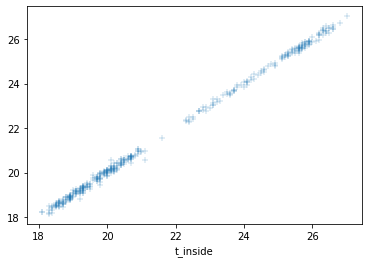

In [15]:
# Create Plots


test_t = output_test["t_inside"]
test_h = output_test["h_inside"]
predicted_t = test_predictions[:,0]
predicted_h = test_predictions[:,1]

# temperature
sns.scatterplot(x = test_t, y = predicted_t, marker="+", alpha=0.5 )

<AxesSubplot:xlabel='h_inside'>

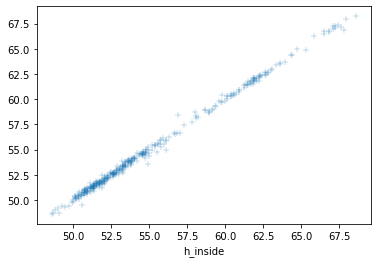

In [11]:
# humidity
sns.scatterplot(x=test_h, y = predicted_h, marker="+", alpha=0.5)

In [12]:
pkl_filename = settings.TRAINED_MODEL_PATH
with open(pkl_filename, 'wb') as file:
    pickle.dump(model, file)